# Cómo entra la señal al modelo y qué cambia en cada caso

Este cuaderno muestra, sobre señales reales del conjunto de prueba, **qué recibe el modelo** en cada una de las
condiciones evaluadas en la tesis y **cómo responde**:

1. La señal I/Q y su espectrograma de entrenamiento (`R64x64`).
2. La huella de cada transmisor.
3. Los tres niveles de cambio de resolución: geométrico (redimensionar), de muestreo (misma ventana) y de análisis
   (ventana = `n_fft`).
4. El barrido de la longitud de la ventana.
5. Parche fijo y parche escalado: qué cubre cada token.
6. Qué ve el modelo: tokens y predicciones en cada caso (requiere los `best.pt`).
7. Resumen numérico de los dos escenarios.

No entrena nada. Todas las figuras se guardan en `figures/notebook/`.

In [2]:
%matplotlib inline
import os, sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "configs").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, torch, torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset

from preprocessing.stft_generator import compute_spectrograms
from scripts.eval_resize import resize_batch
from src.evaluation.eval_resolutions import predict
from src.models import build_model
from src.models.patch_scale import rescale_patch_kernel
from src.training.checkpoint import load_checkpoint
from src.training.data import build_dataset, make_loader, res_hw
from src.training.setup import load_all
from src.utils.config import Cfg, load_config

RUN_VIT = os.environ.get("NB_RUN_VIT", "f1_vit_base_r64")        # corridas de 1 receptor / 1 fecha
RUN_MSVIT = os.environ.get("NB_RUN_MSVIT", "f3_msvit_base_r64")
OUT = Path("figures/notebook"); OUT.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "font.size": 9, "axes.titlesize": 9})

def save(fig, name):
    path = OUT / f"nb__{name}.png"
    fig.savefig(path, bbox_inches="tight"); print("guardada:", path)

cfg = load_config(Path("runs") / RUN_VIT / "config_snapshot.yaml")
pre, subset, splits = load_all(cfg)
TX = [str(t) for t in subset["tx_names"]]
R_TR = cfg.resolution.train
RES = pre.resolutions
HW_TR = tuple(res_hw(RES[R_TR], pre.stft.signal_len))
test_idx = splits["test"]; y_test = subset["y"][test_idx]
print("Transmisores:", TX, "| entrenamiento:", R_TR, HW_TR, "| señales de prueba:", len(test_idx))

def spec(res, idx=test_idx):
    "Espectrogramas (N, 1, F, T) de las señales `idx` con la configuración STFT `res`."
    return build_dataset(subset, idx, res, pre.stft, DEVICE).tensors[0]

def show(ax, img, title="", grid=None, vmin=-2.5, vmax=2.5):
    "Dibuja un espectrograma ocupando siempre el mismo recuadro; `grid`=(ph, pw) superpone la rejilla de parches."
    img = np.asarray(img); Fb, Tb = img.shape
    ax.imshow(img, origin="lower", aspect="auto", cmap="viridis", vmin=vmin, vmax=vmax, extent=(0, 1, 0, 1))
    if grid:
        for k in range(1, Fb // grid[0]): ax.axhline(k * grid[0] / Fb, color="w", lw=0.4, alpha=0.7)
        for k in range(1, Tb // grid[1]): ax.axvline(k * grid[1] / Tb, color="w", lw=0.4, alpha=0.7)
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])

EX = int(np.where(y_test == 0)[0][0])        # señal de ejemplo: la primera de prueba del primer transmisor
X64 = spec(RES[R_TR])                        # todas las señales de prueba en R64x64
print("Señal de ejemplo: índice de prueba", EX, "| transmisor", TX[y_test[EX]])

Transmisores: ['14-10', '14-7', '20-15', '20-19', '6-15', '8-20'] | entrenamiento: R64x64 (64, 64) | señales de prueba: 900
Señal de ejemplo: índice de prueba 0 | transmisor 14-10


## 1. La señal y su espectrograma

Cada señal son 256 muestras complejas (I y Q). El modelo no recibe la señal cruda: recibe el espectrograma
(STFT → potencia en dB → normalización por muestra). A la derecha, la rejilla de parches de cada modelo sobre la
imagen de entrenamiento: el ViT corta parches de 8×8 (64 tokens) y MSViT de 4×4 (256 tokens en la primera etapa).

guardada: figures\notebook\nb__01_senal_y_espectrograma.png


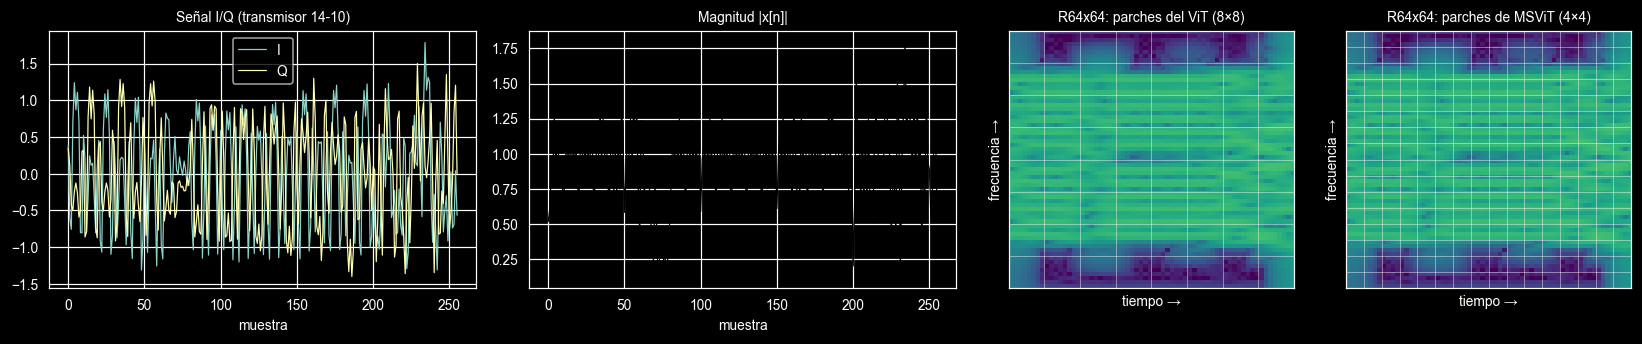

In [3]:
iq = subset["X"][test_idx[EX]]
fig, ax = plt.subplots(1, 4, figsize=(15, 3.2), gridspec_kw={"width_ratios": [1.5, 1.5, 1, 1]})
ax[0].plot(iq[:, 0], lw=0.8, label="I"); ax[0].plot(iq[:, 1], lw=0.8, label="Q")
ax[0].set_title(f"Señal I/Q (transmisor {TX[y_test[EX]]})"); ax[0].set_xlabel("muestra"); ax[0].legend()
ax[1].plot(np.hypot(iq[:, 0], iq[:, 1]), lw=0.8, color="k")
ax[1].set_title("Magnitud |x[n]|"); ax[1].set_xlabel("muestra")
show(ax[2], X64[EX, 0], f"{R_TR}: parches del ViT (8×8)", grid=(8, 8))
show(ax[3], X64[EX, 0], f"{R_TR}: parches de MSViT (4×4)", grid=(4, 4))
for a in ax[2:]: a.set_xlabel("tiempo →"); a.set_ylabel("frecuencia →")
fig.tight_layout(); save(fig, "01_senal_y_espectrograma")

## 2. La huella de cada transmisor

Todos los transmisores envían el mismo preámbulo, así que sus espectrogramas se parecen mucho (fila superior). La
identidad está en diferencias pequeñas: la fila inferior muestra el espectrograma medio de cada transmisor **menos**
el promedio de todos. Ese detalle fino es lo que el modelo aprende, y es lo primero que se altera al cambiar la
representación.

guardada: figures\notebook\nb__02_huella_por_transmisor.png


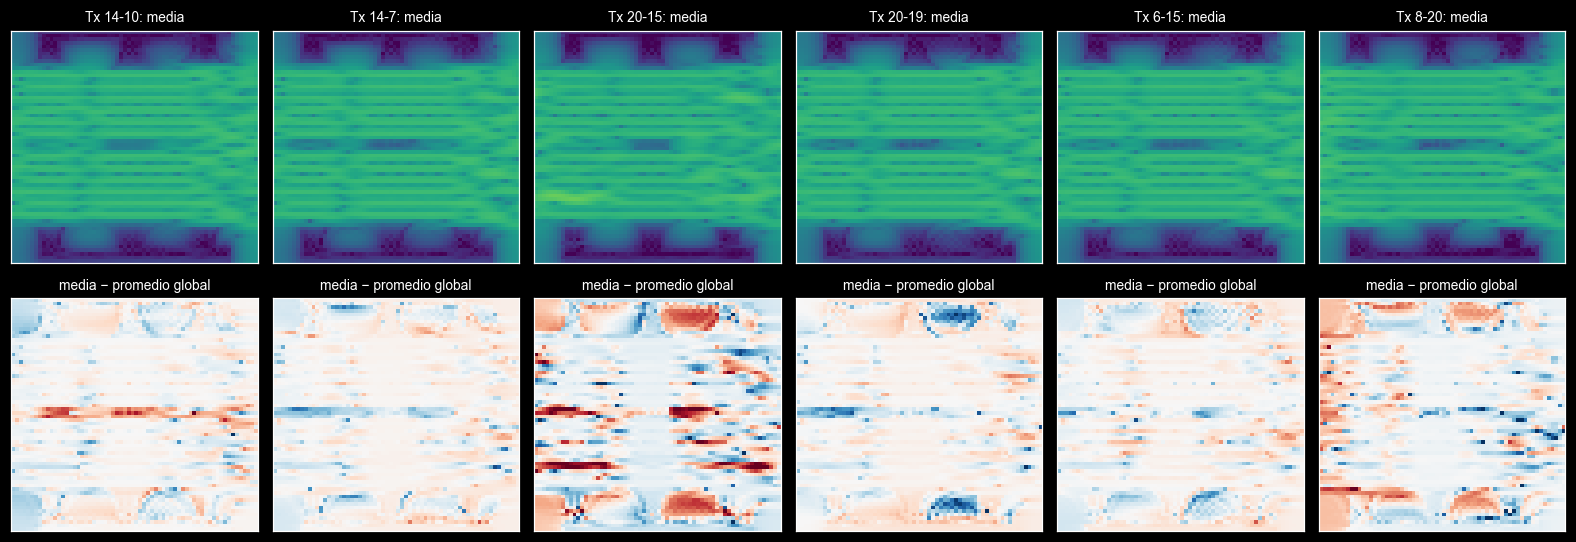

In [4]:
means = torch.stack([X64[torch.from_numpy(y_test == c)].mean(0)[0] for c in range(len(TX))])
glob = means.mean(0)
fig, ax = plt.subplots(2, len(TX), figsize=(2.4 * len(TX), 5))
for c in range(len(TX)):
    show(ax[0, c], means[c], f"Tx {TX[c]}: media")
    d = (means[c] - glob).numpy()
    ax[1, c].imshow(d, origin="lower", aspect="auto", cmap="RdBu_r", vmin=-0.6, vmax=0.6, extent=(0, 1, 0, 1))
    ax[1, c].set_title("media − promedio global"); ax[1, c].set_xticks([]); ax[1, c].set_yticks([])
fig.tight_layout(); save(fig, "02_huella_por_transmisor")

## 3. Los tres niveles de cambio de resolución

Misma señal de ejemplo, llevada a 128×128 de tres formas:

- **Nivel 1, geométrico:** se redimensiona la imagen de 64×64 (vecino más cercano, bilineal, bicúbica). No hay
  información nueva.
- **Nivel 2, muestreo:** se recalcula la STFT con la misma ventana de 64 y más bins y frames
  (`n_fft` = 128 con relleno de ceros, salto 2).
- **Nivel 3, análisis:** se recalcula con ventana de 128 (la definición de resolución de la tesis). Es otro análisis
  de la señal: más detalle en frecuencia, menos en tiempo.

guardada: figures\notebook\nb__03_tres_niveles_128.png


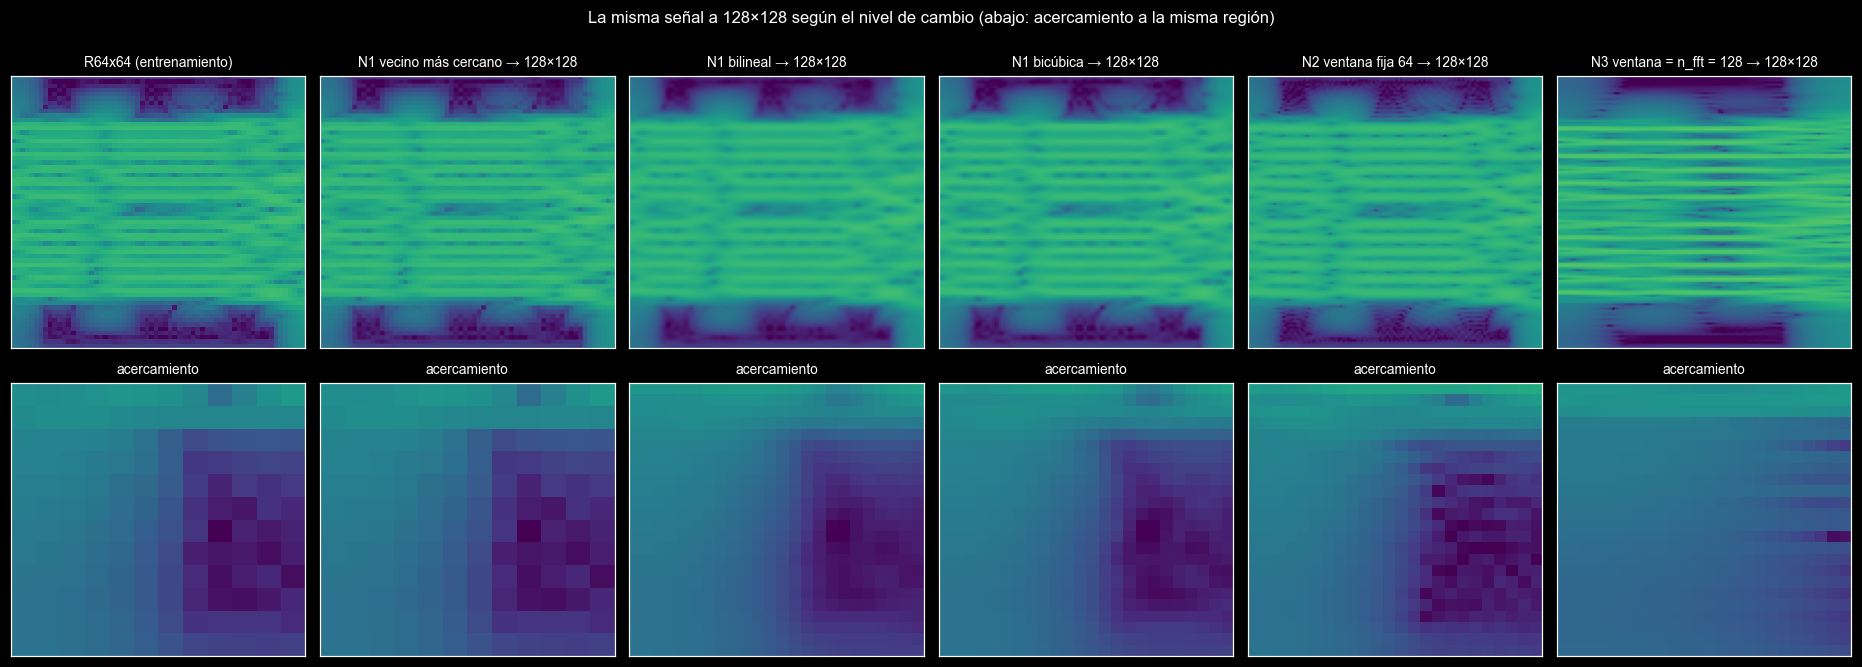

In [5]:
FW = pre.get("resolutions_fixed_window") or {}
x1 = X64[EX:EX + 1]
cases128 = {
    "N1 vecino más cercano": resize_batch(x1, (128, 128), "nearest", True),
    "N1 bilineal": resize_batch(x1, (128, 128), "bilinear", True),
    "N1 bicúbica": resize_batch(x1, (128, 128), "bicubic", True),
    "N2 ventana fija 64": spec(FW["W64_R128x128"], test_idx[EX:EX + 1]),
    "N3 ventana = n_fft = 128": spec(RES["R128x128"], test_idx[EX:EX + 1]),
}
fig, ax = plt.subplots(2, 6, figsize=(17, 6))
show(ax[0, 0], x1[0, 0], f"{R_TR} (entrenamiento)")
for a, (name, img) in zip(ax[0, 1:], cases128.items()):
    show(a, img[0, 0], name + " → 128×128")
z = slice(0, 12)                                   # acercamiento: esquina inferior izquierda (12×12 px del original)
show(ax[1, 0], x1[0, 0, z, z], "acercamiento")
for a, (name, img) in zip(ax[1, 1:], cases128.items()):
    show(a, img[0, 0, 0:24, 0:24], "acercamiento")
fig.suptitle("La misma señal a 128×128 según el nivel de cambio (abajo: acercamiento a la misma región)", y=1.0)
fig.tight_layout(); save(fig, "03_tres_niveles_128")

### Corte en frecuencia

El espectro promediado en el tiempo de la misma señal deja ver la diferencia entre niveles: la interpolación
(nivel 1) solo une los puntos del espectro de 64 bins; la ventana fija con más bins (nivel 2) calcula los valores
intermedios desde la señal y revela estructura entre bins; la ventana más larga (nivel 3) cambia la forma del
espectro, con picos más estrechos.

guardada: figures\notebook\nb__04_corte_en_frecuencia.png


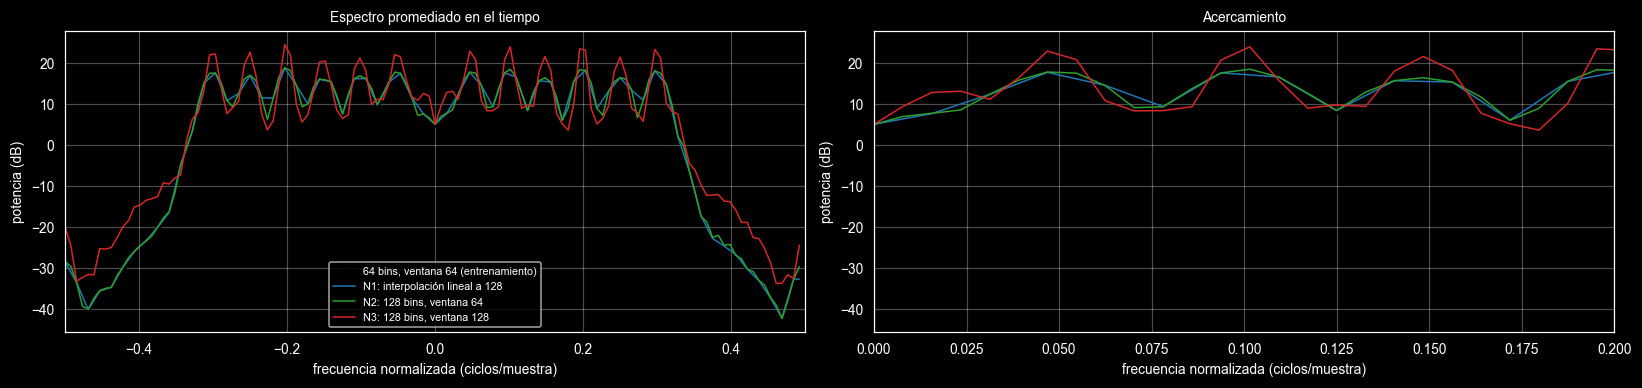

In [6]:
def avg_spectrum(res):
    "Espectro en dB promediado en el tiempo, sin normalizar, de la señal de ejemplo."
    s = compute_spectrograms(torch.from_numpy(subset["X"][test_idx[EX:EX + 1]]), res.n_fft, res.win_len, res.hop,
                             window=pre.stft.window, log_scale=pre.stft.log_scale, normalize=False)
    return s[0].mean(dim=1).numpy()

s64 = avg_spectrum(RES[R_TR]); f64 = (np.arange(64) - 32) / 64
f128 = (np.arange(128) - 64) / 128
fig, ax = plt.subplots(1, 2, figsize=(15, 3.6))
for a, (lo, hi) in zip(ax, [(-0.5, 0.5), (0.0, 0.2)]):
    a.plot(f64, s64, "o", ms=3, color="k", label="64 bins, ventana 64 (entrenamiento)")
    a.plot(f128, np.interp(f128, f64, s64), lw=1, color="tab:blue", label="N1: interpolación lineal a 128")
    a.plot(f128, avg_spectrum(FW["W64_R128x128"]), lw=1, color="tab:green", label="N2: 128 bins, ventana 64")
    a.plot(f128, avg_spectrum(RES["R128x128"]), lw=1, color="tab:red", label="N3: 128 bins, ventana 128")
    a.set_xlim(lo, hi); a.set_xlabel("frecuencia normalizada (ciclos/muestra)"); a.set_ylabel("potencia (dB)"); a.grid(alpha=.3)
ax[0].set_title("Espectro promediado en el tiempo"); ax[1].set_title("Acercamiento"); ax[0].legend(fontsize=7)
fig.tight_layout(); save(fig, "04_corte_en_frecuencia")

### Las resoluciones de la tesis (nivel 3) y su equivalente con ventana fija (nivel 2)

Arriba, las cuatro resoluciones regeneradas con ventana = `n_fft`. Abajo, las mismas formas con la ventana fija en 64.
La rejilla blanca es el parche **fijo** de 8×8 del ViT: al crecer la imagen, cada parche cubre una porción menor de
la señal.

guardada: figures\notebook\nb__05_resoluciones_n3_y_n2.png


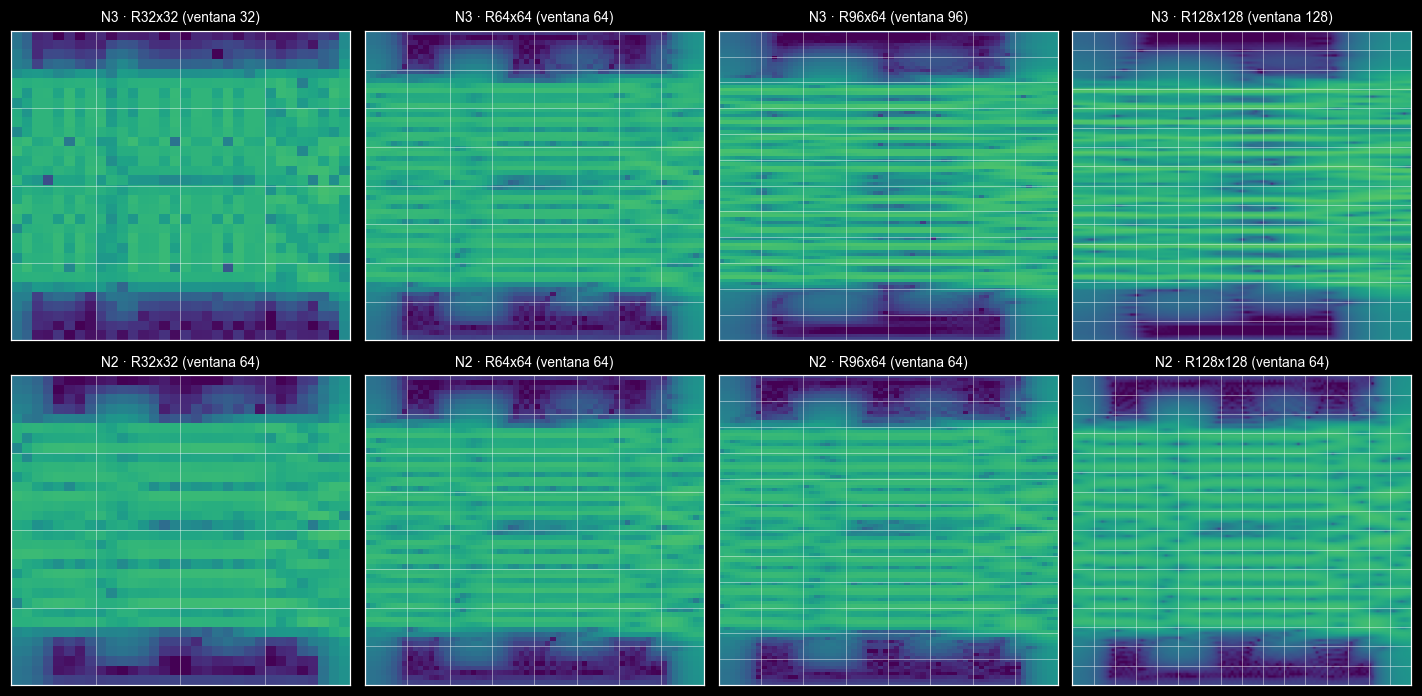

In [7]:
names = ["R32x32", "R64x64", "R96x64", "R128x128"]
fig, ax = plt.subplots(2, 4, figsize=(13, 6.4))
for j, n in enumerate(names):
    a = spec(RES[n], test_idx[EX:EX + 1])[0, 0]
    show(ax[0, j], a, f"N3 · {n} (ventana {RES[n].win_len})", grid=(8, 8))
    key = "W64_" + n
    b = spec(FW[key], test_idx[EX:EX + 1])[0, 0] if key in FW else a
    show(ax[1, j], b, f"N2 · {n} (ventana 64)", grid=(8, 8))
fig.tight_layout(); save(fig, "05_resoluciones_n3_y_n2")

## 4. Barrido de la longitud de la ventana

La imagen se mantiene en 64×64 (mismos bins, mismo salto, mismos parches) y solo cambia la ventana. Con ventanas
cortas el espectro se difumina en frecuencia y se afina en tiempo; con ventanas largas ocurre lo contrario. La
última gráfica es la exactitud de los modelos en este mismo barrido.

guardada: figures\notebook\nb__06_barrido_ventana_imagenes.png
guardada: figures\notebook\nb__07_barrido_ventana_exactitud.png


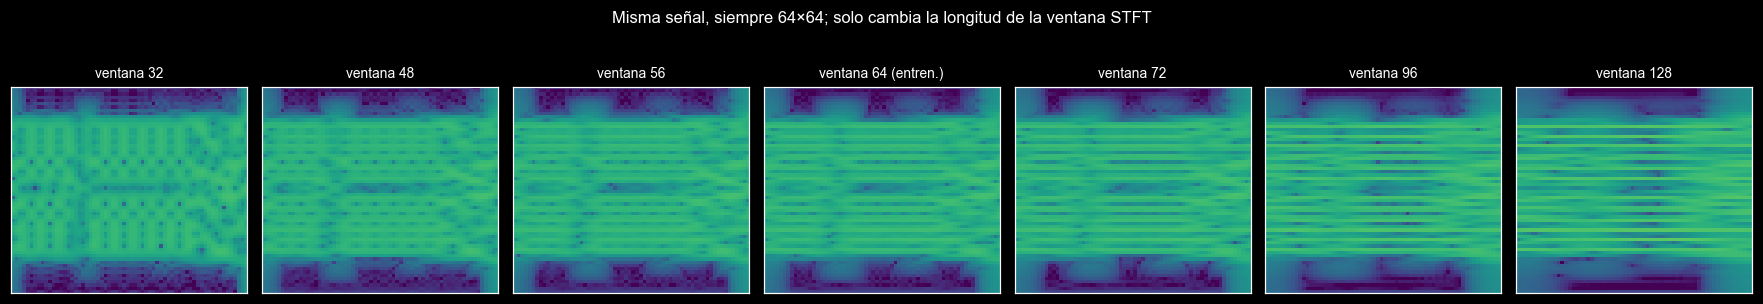

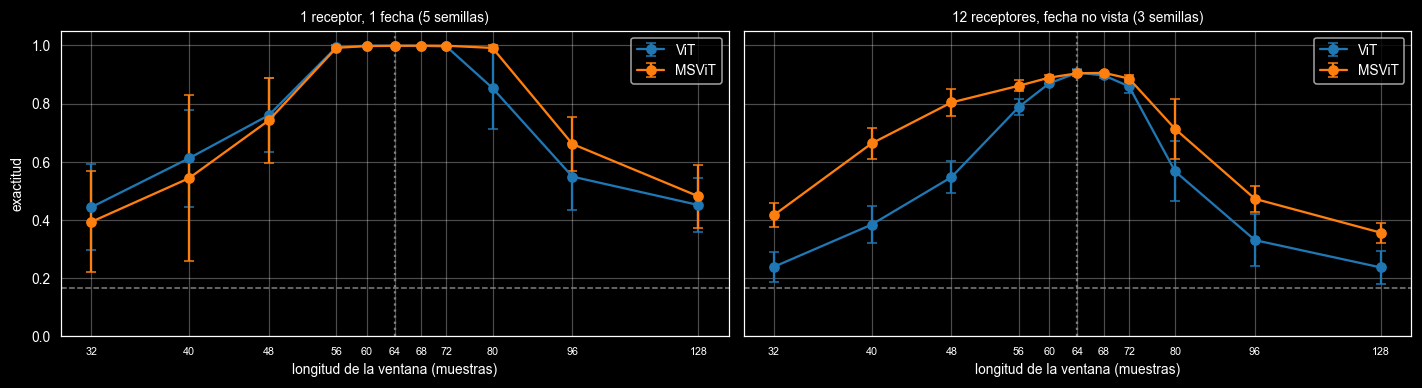

In [8]:
r0 = RES[R_TR]
wins = [32, 48, 56, 64, 72, 96, 128]
fig, ax = plt.subplots(1, len(wins), figsize=(2.3 * len(wins), 2.6))
for a, w in zip(ax, wins):
    img = spec(Cfg(n_fft=r0.n_fft, win_len=w, hop=r0.hop), test_idx[EX:EX + 1])[0, 0]
    show(a, img, f"ventana {w}" + (" (entren.)" if w == r0.win_len else ""))
fig.suptitle("Misma señal, siempre 64×64; solo cambia la longitud de la ventana STFT", y=1.04)
fig.tight_layout(); save(fig, "06_barrido_ventana_imagenes")

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
for a, n, title in zip(ax, (10, 6), ("1 receptor, 1 fecha (5 semillas)", "12 receptores, fecha no vista (3 semillas)")):
    p = Path(f"figures/comparison/window_sweep__summary__n_runs-{n}.csv")
    if not p.exists():
        a.set_title(f"falta {p.name}"); continue
    d = pd.read_csv(p)
    for m, color, lab in (("vit", "tab:blue", "ViT"), ("msvit", "tab:orange", "MSViT")):
        g = d[d["model"] == m]
        a.errorbar(g["win_len"], g["mean"], yerr=g["std"], marker="o", capsize=3, color=color, label=lab)
    a.axvline(r0.win_len, color="gray", ls=":"); a.axhline(1 / len(TX), color="gray", ls="--", lw=1)
    a.set_xscale("log", base=2); a.set_xticks(sorted(d["win_len"].unique())); a.set_xticklabels(sorted(d["win_len"].unique()), fontsize=7)
    a.minorticks_off(); a.set_title(title); a.set_xlabel("longitud de la ventana (muestras)"); a.grid(alpha=.3); a.legend()
ax[0].set_ylabel("exactitud"); ax[0].set_ylim(0, 1.05)
fig.tight_layout(); save(fig, "07_barrido_ventana_exactitud")

## 5. Parche fijo y parche escalado

Con **parche fijo** (izquierda), una imagen de 128×128 se corta en 16×16 parches de 8×8: hay cuatro veces más tokens
y cada uno cubre la cuarta parte del contenido que cubría en entrenamiento. Con **parche escalado** (derecha), el
parche crece a 16×16 y la rejilla vuelve a ser de 8×8: cada token cubre la misma región de la señal que en
entrenamiento. El núcleo del parche se reescala en el dominio DCT, sin pesos nuevos.

guardada: figures\notebook\nb__08_parche_fijo_vs_escalado.png


tokens con parche fijo parche escalado  \
resolución modelo                                           
R32x32     ViT                         16             4×4   
           MSViT                       64             2×2   
R64x64     ViT                         64             8×8   
           MSViT                      256             4×4   
R96x64     ViT                         96            12×8   
           MSViT                      384             6×4   
R128x128   ViT                        256           16×16   
           MSViT                     1024             8×8   

                   tokens con parche escalado  
resolución modelo                              
R32x32     ViT                             64  
           MSViT                          256  
R64x64     ViT                             64  
           MSViT                          256  
R96x64     ViT                             64  
           MSViT                          256  
R128x128   ViT                             64  
           MSViT                          256

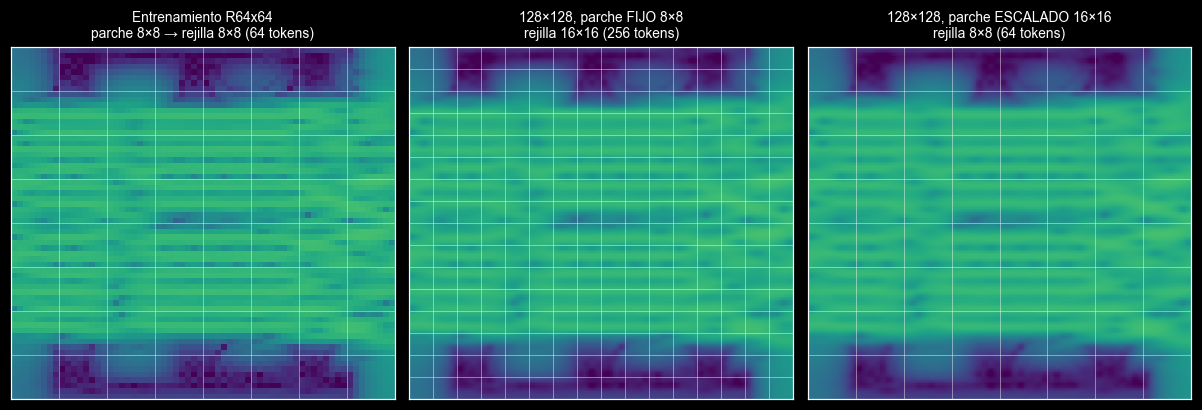

In [9]:
img128 = cases128["N1 bilineal"][0, 0]
fig, ax = plt.subplots(1, 3, figsize=(11, 3.8))
show(ax[0], x1[0, 0], f"Entrenamiento {R_TR}\nparche 8×8 → rejilla 8×8 (64 tokens)", grid=(8, 8))
show(ax[1], img128, "128×128, parche FIJO 8×8\nrejilla 16×16 (256 tokens)", grid=(8, 8))
show(ax[2], img128, "128×128, parche ESCALADO 16×16\nrejilla 8×8 (64 tokens)", grid=(16, 16))
fig.tight_layout(); save(fig, "08_parche_fijo_vs_escalado")

rows = []
for n in names:
    H, W = res_hw(RES[n], pre.stft.signal_len)
    for model, p in (("ViT", 8), ("MSViT", 4)):
        ph, pw = p * H // HW_TR[0], p * W // HW_TR[1]
        rows.append({"resolución": n, "modelo": model, "tokens con parche fijo": (H // p) * (W // p),
                     "parche escalado": f"{ph}×{pw}", "tokens con parche escalado": (H // ph) * (W // pw)})
pd.DataFrame(rows).set_index(["resolución", "modelo"])

## 6. Qué ve el modelo en cada caso

Esta sección usa los modelos entrenados (`runs/<corrida>/checkpoints/best.pt`). Para cada caso se mide:

- **Error de tokens:** diferencia relativa entre los tokens del parche escalado y los tokens que el modelo veía en
  entrenamiento para la misma señal (0 = idénticos). Indica cuánto se parece la entrada efectiva a la aprendida.
- **Predicciones:** a qué transmisor asigna el modelo las señales de prueba, con parche fijo y con parche escalado.
  Una barra dominante significa que el modelo colapsa en una sola clase.

In [10]:
def load_model(run):
    ck = Path("runs") / run / "checkpoints" / "best.pt"
    if not ck.exists():
        print(f"[aviso] no existe {ck}: se omite {run}"); return None
    c = load_config(Path("runs") / run / "config_snapshot.yaml")
    m = build_model(c.model, len(TX), HW_TR)
    m.load_state_dict(load_checkpoint(ck, DEVICE)["model"])
    return m.to(DEVICE).eval()

MODELS = {k: m for k, m in (("ViT", load_model(RUN_VIT)), ("MSViT", load_model(RUN_MSVIT))) if m is not None}

CASES = {   # nombre -> función que devuelve los espectrogramas de prueba (N, 1, F, T)
    "R64x64\n(entrenamiento)": lambda: X64,
    "N1 bilineal\n96×64": lambda: resize_batch(X64, (96, 64), "bilinear", True),
    "N2 vent. fija\n96×64": lambda: spec(FW["W64_R96x64"]),
    "N3 regenerada\n96×64": lambda: spec(RES["R96x64"]),
    "N1 bilineal\n128×128": lambda: resize_batch(X64, (128, 128), "bilinear", True),
    "N2 vent. fija\n128×128": lambda: spec(FW["W64_R128x128"]),
    "N3 regenerada\n128×128": lambda: spec(RES["R128x128"]),
}

@torch.no_grad()
def tokens(model, X):
    "Tokens del patch embedding con parche escalado (misma rejilla que en entrenamiento)."
    X = X.to(DEVICE); H, W = X.shape[-2:]
    pt = (model.p * H // HW_TR[0], model.p * W // HW_TR[1])
    if hasattr(model, "patch_embed"):                                  # ViT
        k = model.patch_embed.weight if pt == (model.p, model.p) else rescale_patch_kernel(model.patch_embed.weight, pt)
        return F.conv2d(X, k, model.patch_embed.bias, stride=pt).cpu()
    return model.stem(X, pt).cpu()                                     # MSViT

def predictions(model, X, scaled):
    model.ref_hw = HW_TR if scaled else None
    yt, yp = predict(model, make_loader(TensorDataset(X, torch.from_numpy(y_test).long()), 256, False), DEVICE)
    model.ref_hw = None
    return np.asarray(yp)

results = []
for cname, make in CASES.items():
    X = make()
    for mname, model in MODELS.items():
        t0, t = tokens(model, X64), tokens(model, X)
        err = ((t - t0).flatten(1).norm(dim=1) / t0.flatten(1).norm(dim=1)).mean().item()
        for scaled in (False, True):
            yp = predictions(model, X, scaled)
            results.append({"caso": cname, "modelo": mname, "parche": "escalado" if scaled else "fijo",
                            "error_tokens": err, "exactitud": float((yp == y_test).mean()),
                            "pred": np.bincount(yp, minlength=len(TX)) / len(yp)})
R = pd.DataFrame(results)
R.pivot_table(index="caso", columns=["modelo", "parche"], values="exactitud", sort=False).round(3) if len(R) else "sin modelos"

modelo                     ViT           MSViT         
parche                    fijo escalado   fijo escalado
caso                                                   
R64x64\n(entrenamiento)  1.000    1.000  0.999    0.999
N1 bilineal\n96×64       0.149    0.999  0.567    0.997
N2 vent. fija\n96×64     0.087    0.999  0.219    1.000
N3 regenerada\n96×64     0.169    0.397  0.083    0.679
N1 bilineal\n128×128     0.167    0.999  0.167    0.997
N2 vent. fija\n128×128   0.167    0.939  0.167    0.987
N3 regenerada\n128×128   0.167    0.244  0.167    0.534

guardada: figures\notebook\nb__09_error_de_tokens.png


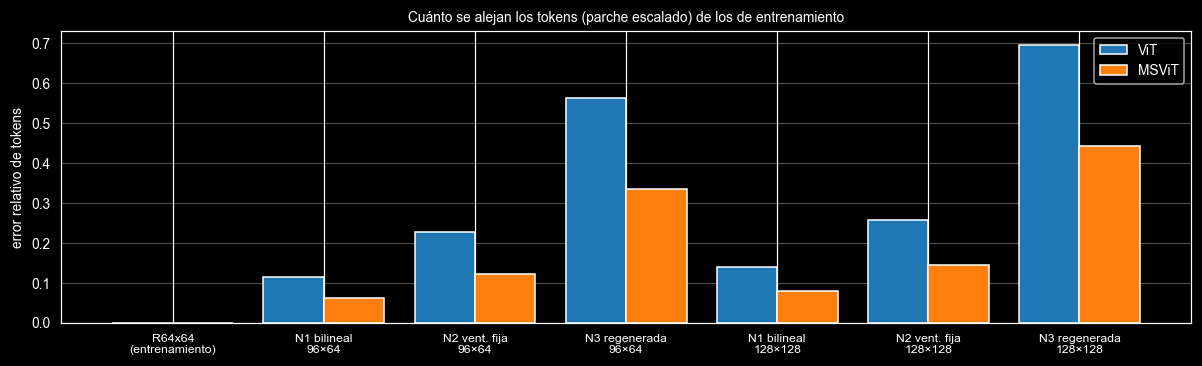

In [11]:
if len(R):
    one = R[R["parche"] == "escalado"]
    fig, ax = plt.subplots(figsize=(11, 3.4))
    cs = list(CASES); w = 0.8 / max(1, len(MODELS))
    for i, (mname, color) in enumerate(zip(MODELS, ("tab:blue", "tab:orange"))):
        v = [one[(one["caso"] == c) & (one["modelo"] == mname)]["error_tokens"].iloc[0] for c in cs]
        ax.bar(np.arange(len(cs)) + (i - (len(MODELS) - 1) / 2) * w, v, w, color=color, label=mname)
    ax.set_xticks(range(len(cs))); ax.set_xticklabels(cs, fontsize=8); ax.grid(alpha=.3, axis="y"); ax.legend()
    ax.set_ylabel("error relativo de tokens"); ax.set_title("Cuánto se alejan los tokens (parche escalado) de los de entrenamiento")
    fig.tight_layout(); save(fig, "09_error_de_tokens")

guardada: figures\notebook\nb__10_predicciones_vit.png
guardada: figures\notebook\nb__10_predicciones_msvit.png


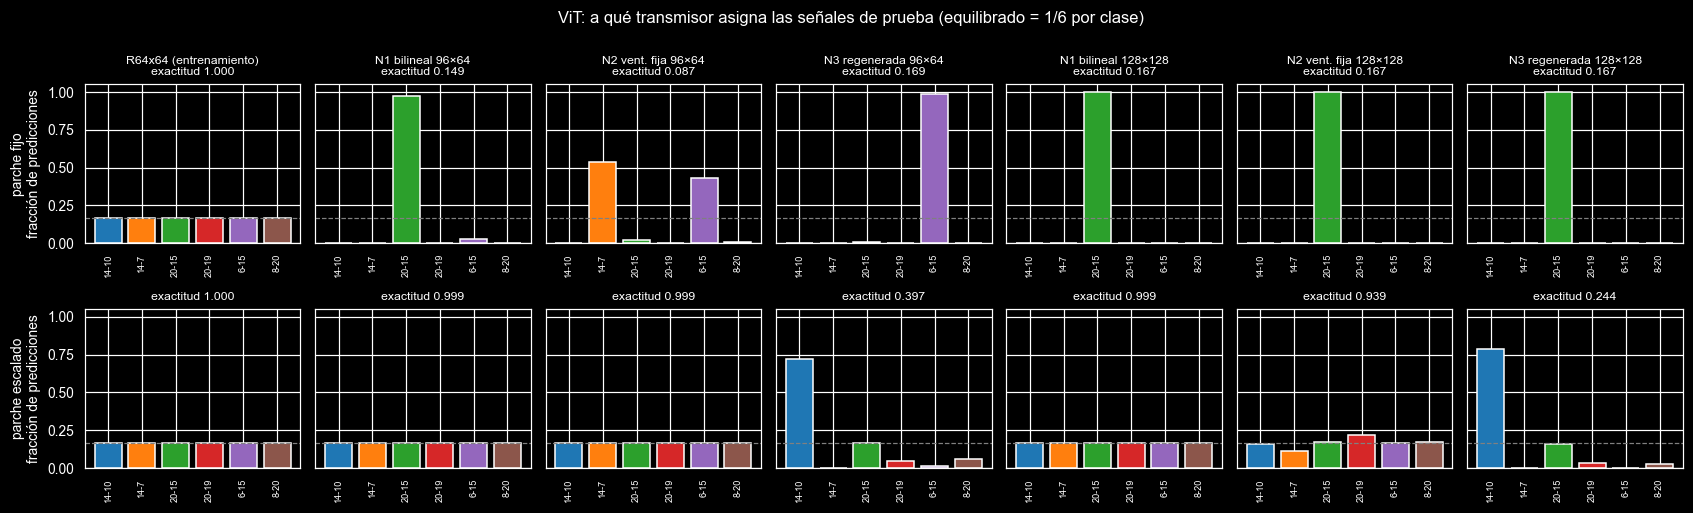

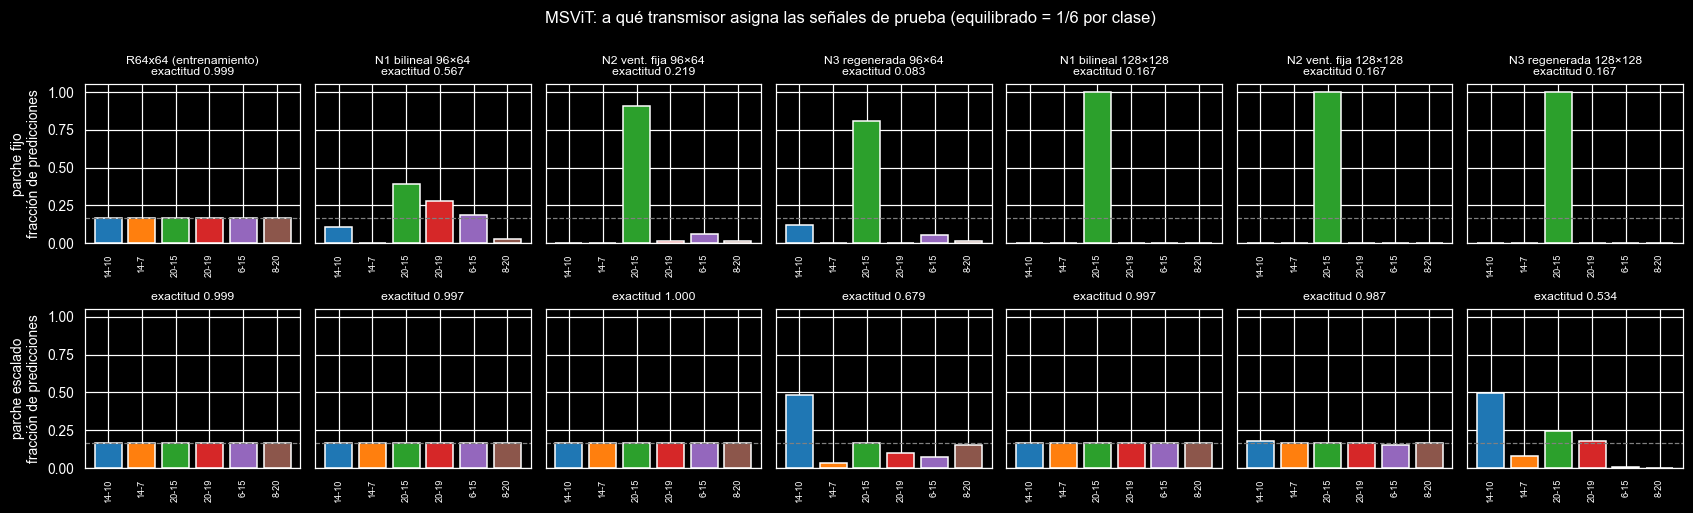

In [12]:
if len(R):
    cs = list(CASES); colors = plt.cm.tab10(np.arange(len(TX)))
    for mname in MODELS:
        fig, ax = plt.subplots(2, len(cs), figsize=(2.2 * len(cs), 4.6), sharey=True)
        for i, parche in enumerate(("fijo", "escalado")):
            for j, c in enumerate(cs):
                r = R[(R["caso"] == c) & (R["modelo"] == mname) & (R["parche"] == parche)].iloc[0]
                ax[i, j].bar(range(len(TX)), r["pred"], color=colors)
                ax[i, j].axhline(1 / len(TX), color="gray", ls="--", lw=0.8)
                ax[i, j].set_title((c.replace("\n", " ") + "\n" if i == 0 else "") + f"exactitud {r['exactitud']:.3f}", fontsize=8)
                ax[i, j].set_xticks(range(len(TX))); ax[i, j].set_xticklabels(TX, rotation=90, fontsize=6)
            ax[i, 0].set_ylabel(f"parche {parche}\nfracción de predicciones")
        fig.suptitle(f"{mname}: a qué transmisor asigna las señales de prueba (equilibrado = 1/{len(TX)} por clase)", y=1.0)
        fig.tight_layout(); save(fig, f"10_predicciones_{mname.lower()}")

## 7. Resumen de los dos escenarios

Exactitud media al **ampliar** la resolución, por nivel, con parche fijo y con parche escalado. Izquierda: modelos
entrenados con un receptor y una fecha (5 semillas). Derecha: doce receptores y prueba en una fecha no vista
(3 semillas). La línea punteada es la exactitud en `R64x64` de cada escenario.

guardada: figures\notebook\nb__11_resumen_tres_niveles.png


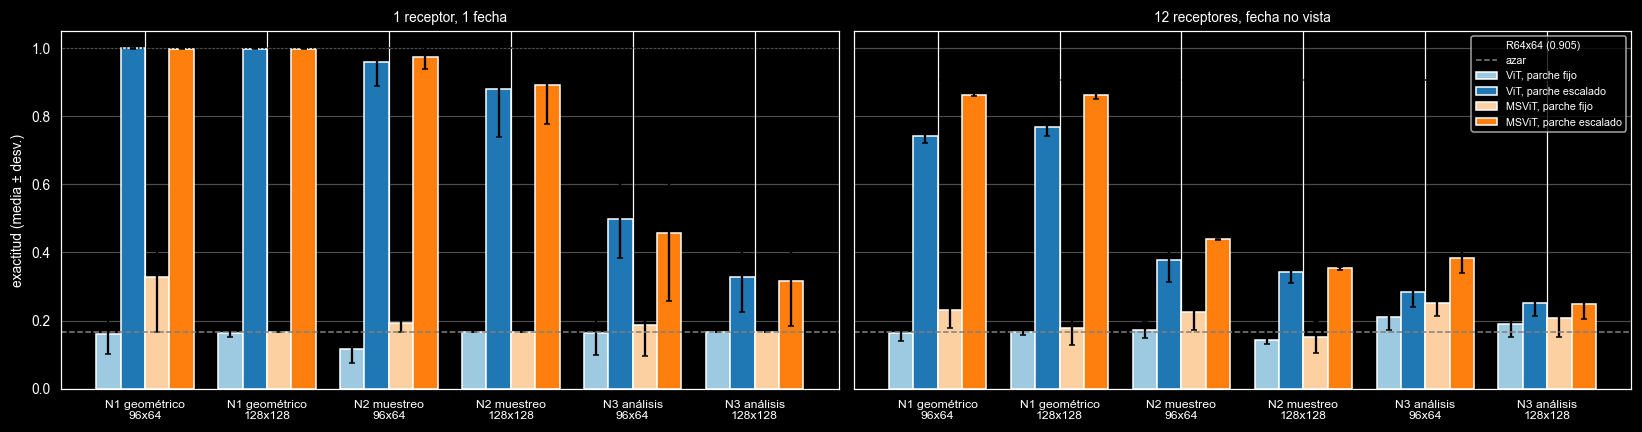

In [13]:
LEVELS = [("redimensionada (bilinear)", "N1 geométrico"), ("STFT de ventana fija", "N2 muestreo"),
          ("STFT regenerada (ventana = n_fft)", "N3 análisis")]
SERIES = [("vit", "fijo", "#9ecae1", "ViT, parche fijo"), ("vit", "escalado", "#1f77b4", "ViT, parche escalado"),
          ("msvit", "fijo", "#fdd0a2", "MSViT, parche fijo"), ("msvit", "escalado", "#ff7f0e", "MSViT, parche escalado")]
fig, ax = plt.subplots(1, 2, figsize=(15, 4), sharey=True)
for a, n, title in zip(ax, (10, 6), ("1 receptor, 1 fecha", "12 receptores, fecha no vista")):
    p = Path(f"figures/comparison/scaled_patch__summary__mode-bilinear_n_runs-{n}.csv")
    if not p.exists():
        a.set_title(f"falta {p.name}"); continue
    d = pd.read_csv(p)
    groups = [(e, lab, r) for e, lab in LEVELS for r in ("R96x64", "R128x128")]
    for i, (m, parche, color, lab) in enumerate(SERIES):
        v = [d[(d["entrada"] == e) & (d["R_test"] == r) & (d["model"] == m) & (d["parche"] == parche)] for e, _, r in groups]
        a.bar(np.arange(len(groups)) + (i - 1.5) * 0.2, [x["mean"].iloc[0] for x in v], 0.2,
              yerr=[x["std"].iloc[0] for x in v], capsize=2, color=color, label=lab)
    base = d[(d["R_test"] == R_TR) & (d["parche"] == "fijo")]["mean"].mean()
    a.axhline(base, color="k", ls=":", lw=1, label=f"{R_TR} ({base:.3f})"); a.axhline(1 / len(TX), color="gray", ls="--", lw=1, label="azar")
    a.set_xticks(range(len(groups))); a.set_xticklabels([f"{lab}\n{r[1:]}" for _, lab, r in groups], fontsize=8)
    a.set_title(title); a.grid(alpha=.3, axis="y"); a.set_ylim(0, 1.05)
ax[0].set_ylabel("exactitud (media ± desv.)"); ax[1].legend(fontsize=7, loc="upper right")
fig.tight_layout(); save(fig, "11_resumen_tres_niveles")

## Lectura

- El modelo recibe una imagen en la que la identidad del transmisor es un detalle fino (sección 2).
- Redimensionar (nivel 1) conserva ese detalle a otra escala; recalcular con la misma ventana (nivel 2) añade
  estructura entre bins; cambiar la ventana (nivel 3) produce otro análisis (sección 3).
- Con parche fijo, los tokens dejan de cubrir lo mismo y el modelo colapsa en una clase; con parche escalado los
  tokens vuelven a parecerse a los de entrenamiento en el nivel 1, menos en el nivel 2 y poco en el nivel 3
  (secciones 5 y 6).
- La tolerancia al cambio de ventana es un margen estrecho alrededor de la ventana de entrenamiento (sección 4).